Num GPUs Available:  1
Train subfolders: ['BACTERIAL', 'NORMAL', 'VIRAL']
First 5 test files: ['IM-0016_normal_0001.jpeg', 'IM-0017_normal_-0001.jpeg', 'IM-0019_normal_-0001.jpeg', 'IM-0021_normal_-0001.jpeg', 'IM-0023_normal_-0001.jpeg']

Training samples: 5216 (Normal=1341, Pneumonia=3875)
Test samples:     40 (Normal=10, Pneumonia=30)
After split: Train=4433, Val=783, Test=40
Class weights: {0: np.float64(1.9442982456140352), 1: np.float64(0.6730944427573641)}
Found 4433 validated image filenames.
Found 783 validated image filenames.
Found 40 validated image filenames.
Batch shape: (32, 224, 224, 3), labels: [0 1 0 1 1]


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,300,161 (27.85 MB)

 Trainable params: 262,657 (1.00 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

Epoch 1/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 708ms/step - accuracy: 0.5906 - auc: 0.6305 - loss: 0.8014 - precision: 0.8095 - recall: 0.5829
Epoch 1: val_auc improved from None to 0.97646, saving model to best_model_stage1.keras

Epoch 1: finished saving model to best_model_stage1.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 160s 950ms/step - accuracy: 0.6810 - auc: 0.7560 - loss: 0.6291 - precision: 0.8629 - recall: 0.6784 - val_accuracy: 0.8633 - val_auc: 0.9765 - val_loss: 0.3518 - val_precision: 0.9917 - val_recall: 0.8230 - learning_rate: 1.0000e-04
Epoch 2/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 622ms/step - accuracy: 0.8103 - auc: 0.8962 - loss: 0.4089 - precision: 0.9358 - recall: 0.7983
Epoch 2: val_auc improved from 0.97646 to 0.98063, saving model to best_model_stage1.keras

Epoch 2: finished saving model to best_model_stage1.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 96s 692ms/step - accuracy: 0.8195 - auc: 0.9040 - loss: 0.3952 - precision: 0.9360 - recall: 0.8126 - val_accuracy: 0.8672 - val_auc:

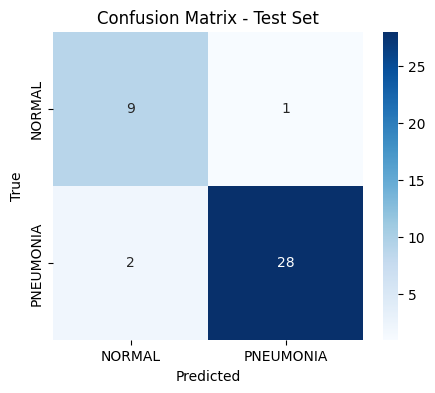

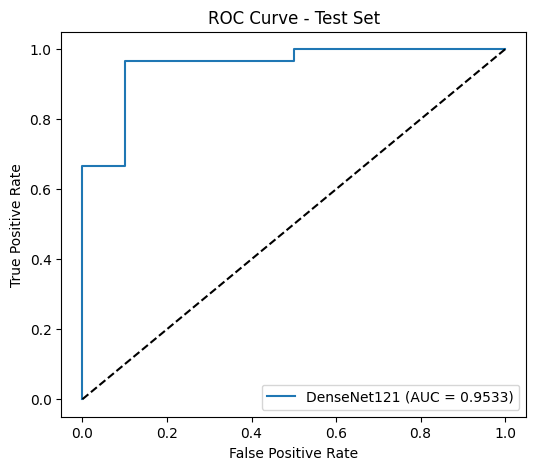

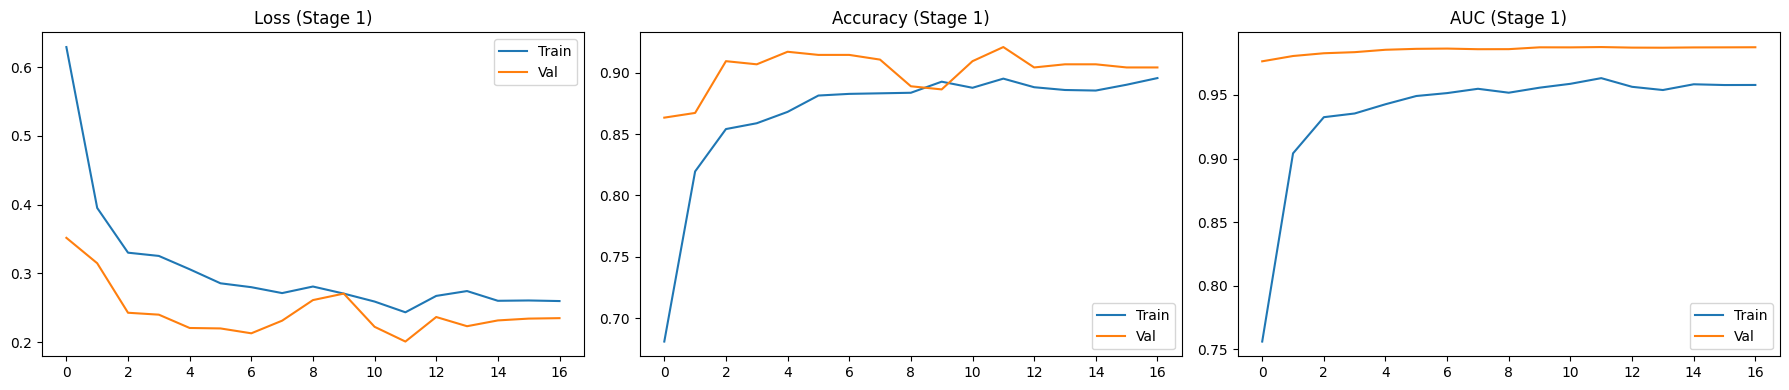

KeyError: 'auc'

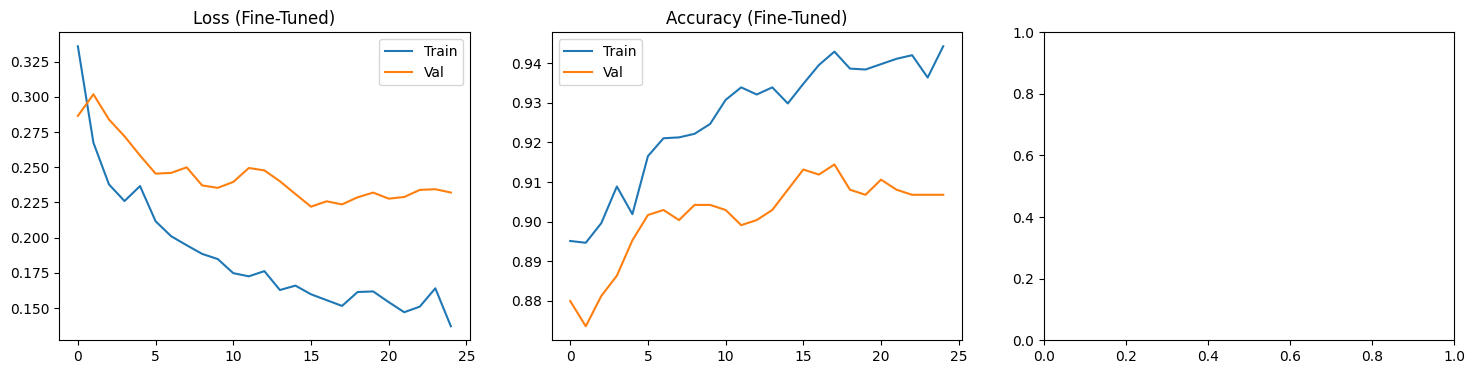

In [3]:
# %% [markdown]
# # Pneumonia Detection (Binary) – Final Pipeline (divyam6969 Dataset)
# **Dataset:** /kaggle/input/datasets/divyam6969/chest-xray-pneumonia-dataset  
# Training: subfolders `BACTERIAL`, `VIRAL`, `NORMAL` → merged to NORMAL / PNEUMONIA  
# Test: flat files, labels inferred from filenames  
# Model: DenseNet121 transfer learning with class weights & Grad‑CAM

# %% [code]
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import cv2
from glob import glob
import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# GPU
print("Num GPUs Available: ", len(tf.config.experimental.list_physical_devices('GPU')))
if tf.config.experimental.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(tf.config.experimental.list_physical_devices('GPU')[0], True)

# %% [markdown]
# ## 1. Load & label data

# %% [code]
BASE_PATH = '/kaggle/input/datasets/divyam6969/chest-xray-pneumonia-dataset'
TRAIN_PATH = os.path.join(BASE_PATH, 'train')
TEST_PATH  = os.path.join(BASE_PATH, 'test')

print("Train subfolders:", sorted(os.listdir(TRAIN_PATH)))
print("First 5 test files:", sorted(os.listdir(TEST_PATH))[:5])

# ---- Training data: already in BACTERIAL, VIRAL, NORMAL subfolders ----
def get_train_files_and_labels(train_dir):
    normal_files = glob(os.path.join(train_dir, 'NORMAL', '*.*'))
    pneumonia_files = []
    for pf in ['BACTERIAL', 'VIRAL']:
        pneumonia_files.extend(glob(os.path.join(train_dir, pf, '*.*')))
    files = normal_files + pneumonia_files
    labels = [0]*len(normal_files) + [1]*len(pneumonia_files)
    return files, labels

train_files, train_labels = get_train_files_and_labels(TRAIN_PATH)

# ---- Test data: flat, infer label from filename ----
def label_from_filename(filename):
    name = os.path.basename(filename).lower()
    if 'normal' in name:
        return 0
    elif 'bacteria' in name or 'virus' in name:
        return 1
    else:
        raise ValueError(f"Cannot determine label for {filename}")

test_files = sorted(glob(os.path.join(TEST_PATH, '*.*')))
test_files = [f for f in test_files if f.lower().endswith(('png','jpg','jpeg','tif','tiff'))]
test_labels = [label_from_filename(f) for f in test_files]

print(f"\nTraining samples: {len(train_files)} (Normal={train_labels.count(0)}, Pneumonia={train_labels.count(1)})")
print(f"Test samples:     {len(test_files)} (Normal={test_labels.count(0)}, Pneumonia={test_labels.count(1)})")

# Build DataFrames
train_df = pd.DataFrame({'filename': train_files, 'class': train_labels})
test_df  = pd.DataFrame({'filename': test_files, 'class': test_labels})

# Create validation split from training (15%, stratified)
train_df, val_df = train_test_split(
    train_df,
    test_size=0.15,
    random_state=SEED,
    stratify=train_df['class']
)
print(f"After split: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")

# Class weights on training set
class_weights_arr = compute_class_weight(
    'balanced',
    classes=np.unique(train_df['class']),
    y=train_df['class']
)
class_weight = {0: class_weights_arr[0], 1: class_weights_arr[1]}
print(f"Class weights: {class_weight}")

# %% [markdown]
# ## 2. Data Generators

# %% [code]
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)

valid_test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='raw',
    shuffle=True,
    seed=SEED
)

val_generator = valid_test_datagen.flow_from_dataframe(
    val_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='raw',
    shuffle=False
)

test_generator = valid_test_datagen.flow_from_dataframe(
    test_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='raw',
    shuffle=False
)

x_batch, y_batch = next(train_generator)
print(f"Batch shape: {x_batch.shape}, labels: {y_batch[:5]}")

# %% [markdown]
# ## 3. DenseNet121 Model

# %% [code]
def build_model():
    base_model = DenseNet121(
        weights='imagenet',
        include_top=False,
        input_shape=(*IMG_SIZE, 3)
    )
    base_model.trainable = False

    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy',
                 tf.keras.metrics.Precision(name='precision'),
                 tf.keras.metrics.Recall(name='recall'),
                 tf.keras.metrics.AUC(name='auc')]
    )
    return model

model = build_model()
model.summary()

# %% [markdown]
# ## 4. Stage‑1 Training (Frozen Base)

# %% [code]
early_stop = EarlyStopping(monitor='val_auc', patience=5, mode='max', restore_best_weights=True, verbose=1)
reduce_lr  = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-7, verbose=1)
checkpoint = ModelCheckpoint('best_model_stage1.keras', monitor='val_auc', mode='max', save_best_only=True, verbose=1)

EPOCHS_STAGE1 = 30
history1 = model.fit(
    train_generator,
    epochs=EPOCHS_STAGE1,
    validation_data=val_generator,
    class_weight=class_weight,
    callbacks=[early_stop, reduce_lr, checkpoint]
)

# %% [markdown]
# ## 5. Fine‑Tuning (Unfreeze top layers)

# %% [code]
model.load_weights('best_model_stage1.keras')

base_model = model.layers[1]  # DenseNet121
base_model.trainable = True
for layer in base_model.layers[:-50]:
    layer.trainable = False

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall(), tf.keras.metrics.AUC()]
)

early_stop_ft = EarlyStopping(monitor='val_auc', patience=8, mode='max', restore_best_weights=True, verbose=1)
reduce_lr_ft  = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=4, min_lr=1e-8, verbose=1)
checkpoint_ft = ModelCheckpoint('best_model_finetuned.keras', monitor='val_auc', mode='max', save_best_only=True, verbose=1)

EPOCHS_FT = 25
history_ft = model.fit(
    train_generator,
    epochs=EPOCHS_FT,
    validation_data=val_generator,
    class_weight=class_weight,
    callbacks=[early_stop_ft, reduce_lr_ft, checkpoint_ft]
)

# %% [markdown]
# ## 6. Evaluate on Test Set

# %% [code]
model.load_weights('best_model_finetuned.keras')

test_generator.reset()
pred_probs = model.predict(test_generator, verbose=1)
pred_classes = (pred_probs > 0.5).astype(int).flatten()
true_classes = test_df['class'].values

print("\nClassification Report (Test Set):")
print(classification_report(true_classes, pred_classes, target_names=['NORMAL', 'PNEUMONIA']))

cm = confusion_matrix(true_classes, pred_classes)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['NORMAL','PNEUMONIA'], yticklabels=['NORMAL','PNEUMONIA'])
plt.title('Confusion Matrix - Test Set')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

auc_score = roc_auc_score(true_classes, pred_probs)
fpr, tpr, _ = roc_curve(true_classes, pred_probs)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'DenseNet121 (AUC = {auc_score:.4f})')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend()
plt.show()

# %% [markdown]
# ## 7. Training Curves

# %% [code]
def plot_history(history, title=''):
    fig, axes = plt.subplots(1, 3, figsize=(18,4))
    axes[0].plot(history.history['loss'], label='Train')
    axes[0].plot(history.history['val_loss'], label='Val')
    axes[0].set_title(f'Loss {title}')
    axes[0].legend()
    axes[1].plot(history.history['accuracy'], label='Train')
    axes[1].plot(history.history['val_accuracy'], label='Val')
    axes[1].set_title(f'Accuracy {title}')
    axes[1].legend()
    axes[2].plot(history.history['auc'], label='Train')
    axes[2].plot(history.history['val_auc'], label='Val')
    axes[2].set_title(f'AUC {title}')
    axes[2].legend()
    plt.tight_layout()
    plt.show()

plot_history(history1, '(Stage 1)')
plot_history(history_ft, '(Fine-Tuned)')

# %% [markdown]
# ## 8. Grad‑CAM Visualization (Fixed)

# %% [code]
def get_img_array(img_path, size):
    img = keras.preprocessing.image.load_img(img_path, target_size=size)
    array = keras.preprocessing.image.img_to_array(img)
    array = np.expand_dims(array, axis=0)
    return preprocess_input(array)

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    # Access the DenseNet121 base model correctly
    base_model = model.get_layer('densenet121')
    grad_model = keras.models.Model(
        inputs=model.inputs,
        outputs=[base_model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, 0]   # pneumonia probability
    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(tf.multiply(pooled_grads, conv_outputs), axis=-1)
    heatmap = np.maximum(heatmap, 0) / (np.max(heatmap) + 1e-8)
    return heatmap.numpy()

def display_gradcam(img_path, heatmap, alpha=0.4):
    img = keras.preprocessing.image.load_img(img_path)
    img = keras.preprocessing.image.img_to_array(img)
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    superimposed = cv2.addWeighted(cv2.cvtColor(img.astype('uint8'), cv2.COLOR_RGB2BGR), 1-alpha, heatmap, alpha, 0)
    plt.figure(figsize=(10,5))
    plt.subplot(1,2,1)
    plt.imshow(keras.preprocessing.image.array_to_img(img))
    plt.title('Original X‑ray')
    plt.axis('off')
    plt.subplot(1,2,2)
    plt.imshow(cv2.cvtColor(superimposed, cv2.COLOR_BGR2RGB))
    plt.title('Grad‑CAM')
    plt.axis('off')
    plt.show()

# Pick a random pneumonia test image
pneumonia_test_indices = test_df[test_df['class'] == 1].index
random_idx = np.random.choice(pneumonia_test_indices)
img_path = test_df.loc[random_idx, 'filename']
print(f"Grad‑CAM for: {os.path.basename(img_path)}")

# Find the last convolutional layer inside DenseNet121
base_model_dn = model.get_layer('densenet121')
last_conv_layer = None
for layer in base_model_dn.layers:
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer = layer.name
print(f"Using last conv layer: {last_conv_layer}")

img_array = get_img_array(img_path, IMG_SIZE)
heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer)
display_gradcam(img_path, heatmap)

print("\n✅ Training, evaluation, and Grad‑CAM complete.")